# Exercício 03 — Filtragem de ruídos de migração com FCNN e SVM-RBF

Neste exercício, comparei uma FCNN e um SVM com kernel RBF na filtragem de uma imagem sísmica migrada, seguindo o laboratório *Identifying Migration Artifacts and Reflectors by Machine Learning Methods*. Meu interesse foi entender como métodos que já conheço de Machine Learning se comportam neste problema de geofísica: além de ajustar os pontos anotados, eles precisam preservar a continuidade dos refletores e remover os eventos associados à migração.

O fluxo experimental é:

1. carregar a imagem de migração e os atributos de coerência, ângulo local e amplitude;
2. normalizar os três atributos como no MATLAB;
3. selecionar 50 artefatos e 30 refletores na primeira execução e salvar as coordenadas em CSV;
4. treinar a FCNN e o SVM-RBF com os parâmetros do laboratório;
5. classificar todos os 40.401 pixels e filtrar a imagem;
6. comparar métricas, máscaras e imagens resultantes.

Fonte: [laboratório oficial](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.SVM/lab.html).

## Protocolo e limites da comparação

Como no laboratório original, o intérprete seleciona exemplos diretamente sobre a imagem. Na primeira execução, um anotador Plotly não bloqueante solicita primeiro 50 artefatos e depois 30 refletores, grava as coordenadas em `annotations.csv` e mostra a seleção em tempo real. Nas execuções seguintes, o mesmo CSV é carregado, tornando o experimento determinístico e auditável.

A classe `1` representa refletor/sinal a preservar e a classe `0` representa artefato ou fundo a remover. As métricas de acurácia são calculadas sobre os próprios 80 pontos usados no treinamento, exatamente no espírito do laboratório. Elas verificam o ajuste, mas **não estimam generalização**. Como não existe uma máscara de referência para todos os pixels, a classificação da imagem completa também deve ser avaliada visualmente e por medidas descritivas, sem tratá-las como verdade de terreno.

In [1]:
from __future__ import annotations

from io import BytesIO
from hashlib import sha256
from pathlib import Path
from urllib.request import Request, urlopen
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.io import loadmat
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.svm import SVC

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 9})
pd.options.display.float_format = "{:.6g}".format
pd.options.display.max_rows = 100

RANDOM_SEED = 42
EXERCISE03_DIR = Path("exercise03") if Path("exercise03/exercise03.ipynb").exists() else Path(".")
ANNOTATIONS_PATH = EXERCISE03_DIR / "annotations.csv"
LAB_ZIP_CACHE_PATH = EXERCISE03_DIR / ".cache" / "Comparision.zip"
LAB_ZIP_URL = "http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.Book.SVM/Comparision.zip"
EXPECTED_ZIP_SHA256 = 'e8618f468c32baa06f714e73c2a02bac5b5e399d44fd70666119219a4c606e6a'

## 1. Aquisição e verificação dos dados

In [2]:
def package_hash(content: bytes) -> str:
    return sha256(content).hexdigest()


zip_bytes: bytes | None = None
package_source = "download"

if LAB_ZIP_CACHE_PATH.exists():
    try:
        cached_bytes = LAB_ZIP_CACHE_PATH.read_bytes()
        cached_hash = package_hash(cached_bytes)
        if cached_hash == EXPECTED_ZIP_SHA256:
            zip_bytes = cached_bytes
            package_source = f"cache ({LAB_ZIP_CACHE_PATH})"
        else:
            print(
                f"Cache inválido ignorado: SHA-256 {cached_hash}; "
                f"esperado {EXPECTED_ZIP_SHA256}."
            )
    except OSError as error:
        print(f"Não foi possível ler o cache ({error}); será feito novo download.")

if zip_bytes is None:
    request = Request(LAB_ZIP_URL, headers={"User-Agent": "exercise03-notebook/1.0"})
    # O laboratório publica este arquivo apenas por HTTP. Por isso, o download
    # é aceito somente quando coincide com o SHA-256 conhecido e fixado.
    with urlopen(request, timeout=60) as response:
        downloaded_bytes = response.read()

    downloaded_hash = package_hash(downloaded_bytes)
    if downloaded_hash != EXPECTED_ZIP_SHA256:
        raise RuntimeError(
            "O pacote oficial mudou: "
            f"SHA-256 esperado {EXPECTED_ZIP_SHA256}, obtido {downloaded_hash}. "
            "Inspecione a nova versão antes de atualizar o hash."
        )
    zip_bytes = downloaded_bytes

    # Gravação atômica: um download interrompido nunca substitui um cache válido.
    temporary_cache = LAB_ZIP_CACHE_PATH.with_suffix(".zip.tmp")
    try:
        LAB_ZIP_CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
        temporary_cache.write_bytes(zip_bytes)
        temporary_cache.replace(LAB_ZIP_CACHE_PATH)
    except OSError as error:
        print(f"Aviso: os dados foram carregados, mas o cache não pôde ser salvo: {error}")

verified_hash = package_hash(zip_bytes)
assert verified_hash == EXPECTED_ZIP_SHA256

with ZipFile(BytesIO(zip_bytes)) as archive:
    member = "Comparision/mig_and_features.mat"
    if member not in archive.namelist():
        raise KeyError(f"{member} não foi encontrado no pacote do laboratório")
    matlab_data = loadmat(BytesIO(archive.read(member)))

migration = np.asarray(matlab_data["mig"], dtype=np.float64)
coherency = np.asarray(matlab_data["cohe"], dtype=np.float64)
angle = np.asarray(matlab_data["angl"], dtype=np.float64)
amplitude = np.asarray(matlab_data["engy"], dtype=np.float64)

arrays = {"migração": migration, "coerência": coherency, "ângulo": angle, "amplitude": amplitude}
for name, array in arrays.items():
    assert array.shape == (201, 201), f"Forma inesperada para {name}: {array.shape}"
    assert np.isfinite(array).all(), f"{name} contém valores não finitos"

print(f"Pacote verificado: {len(zip_bytes):,} bytes")
print(f"Origem: {package_source}")
print(f"SHA-256: {verified_hash}")
print("Matrizes carregadas:", {name: value.shape for name, value in arrays.items()})

Pacote verificado: 2,087,546 bytes
Origem: cache (.cache/Comparision.zip)
SHA-256: e8618f468c32baa06f714e73c2a02bac5b5e399d44fd70666119219a4c606e6a
Matrizes carregadas: {'migração': (201, 201), 'coerência': (201, 201), 'ângulo': (201, 201), 'amplitude': (201, 201)}


### Normalização dos atributos

O MATLAB não usa o desvio-padrão: cada atributo $x$ é centralizado pela média e dividido pela amplitude total de seus valores,

$$x_{norm}=\frac{x-\bar{x}}{\max(x)-\min(x)}.$$

A mesma transformação é aplicada abaixo, sem ajustar qualquer estatística aos rótulos.

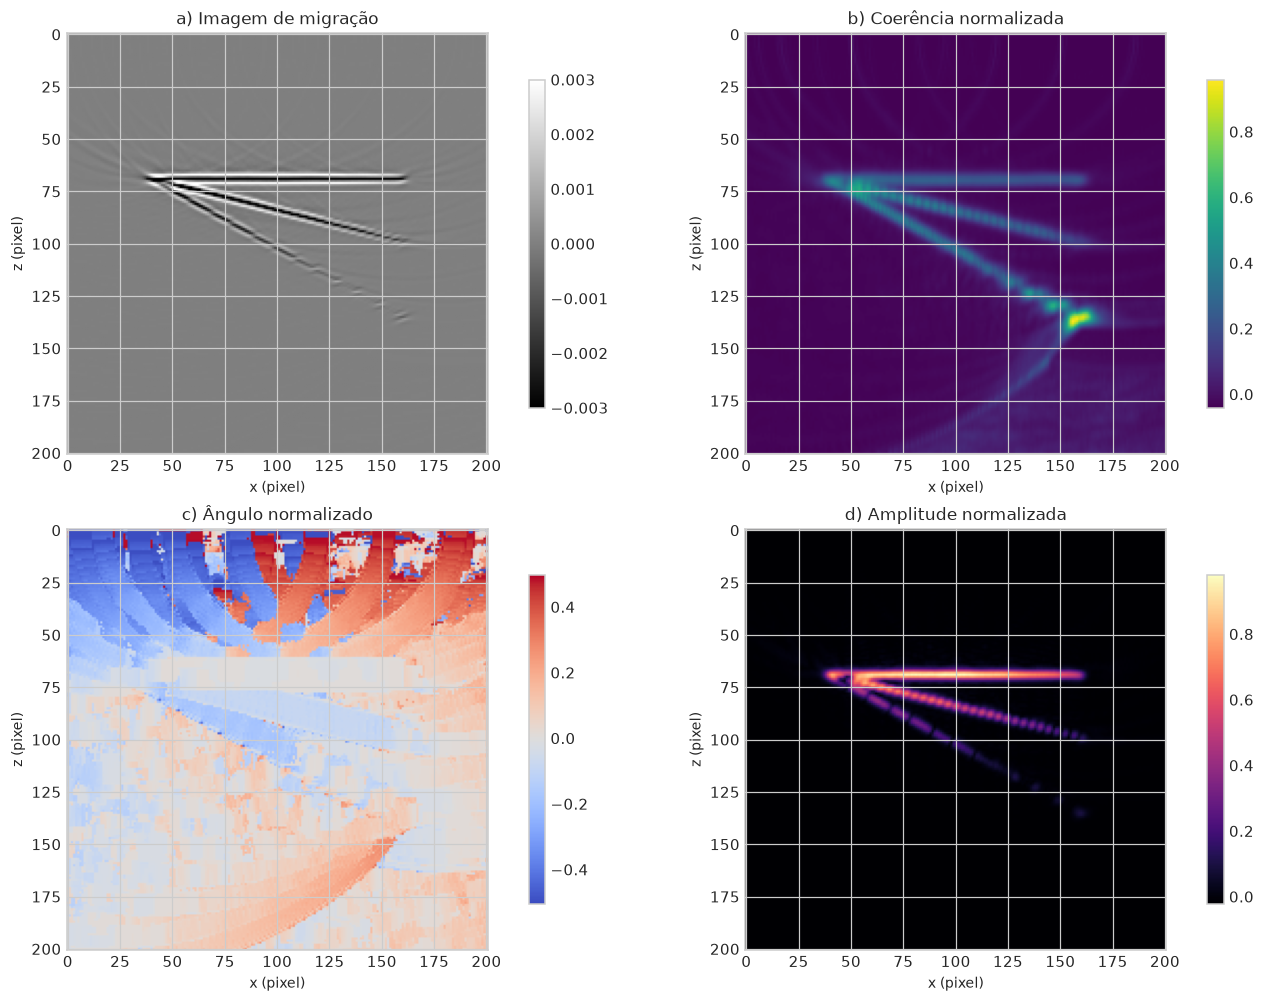

In [3]:
def matlab_scale(array: np.ndarray) -> np.ndarray:
    value_range = float(array.max() - array.min())
    if value_range == 0.0:
        raise ValueError("Não é possível normalizar um atributo constante")
    return (array - array.mean()) / value_range


coherency_scaled = matlab_scale(coherency)
angle_scaled = matlab_scale(angle)
amplitude_scaled = matlab_scale(amplitude)
feature_cube = np.stack(
    [coherency_scaled, angle_scaled, amplitude_scaled], axis=-1
)

assert feature_cube.shape == (201, 201, 3)
assert np.isfinite(feature_cube).all()

fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
panels = [
    ("a) Imagem de migração", migration, "gray", (-0.003, 0.003)),
    ("b) Coerência normalizada", coherency_scaled, "viridis", None),
    ("c) Ângulo normalizado", angle_scaled, "coolwarm", None),
    ("d) Amplitude normalizada", amplitude_scaled, "magma", None),
]
for ax, (title, values, cmap, limits) in zip(axes.flat, panels):
    kwargs = {} if limits is None else {"vmin": limits[0], "vmax": limits[1]}
    image = ax.imshow(values, cmap=cmap, aspect="equal", **kwargs)
    ax.set(title=title, xlabel="x (pixel)", ylabel="z (pixel)")
    fig.colorbar(image, ax=ax, shrink=0.78)
plt.show()

Na minha leitura da imagem, as interfaces mais fortes e contínuas são as principais candidatas a refletores. Os arcos mais fracos são candidatos a artefatos de migração. Essa interpretação orientou a seleção dos pontos, mas não é uma regra absoluta: um refletor pode ter baixa amplitude e um artefato pode apresentar amplitude ou coerência elevadas.

Coerência, ângulo local e amplitude oferecem informações complementares sobre o evento. A amplitude indica sua intensidade, enquanto os outros atributos ajudam a caracterizar sua organização local. Ainda assim, os modelos recebem apenas esses três valores por pixel; não recebem a posição na imagem nem uma vizinhança que permita avaliar diretamente a continuidade de uma interface.

## 2. Seleção manual e persistência das anotações

Se `annotations.csv` não existir, um anotador Plotly aparecerá abaixo. Clique na imagem para selecionar primeiro **50 artefatos (`0`)** e depois **30 refletores (`1`)**. O painel mostra a contagem e muda de classe automaticamente. Use **Desfazer** ou **Limpar tudo** quando necessário; ao final, revise os marcadores e clique em **Salvar CSV**.

Distribua os negativos pelos arcos elípticos de aliasing e escolha os positivos sobre interfaces fortes e contínuas. Evite cruzamentos evidentes, nos quais um mesmo pixel pode misturar sinal e artefato. Depois de salvar, execute a próxima célula. O CSV é validado e reutilizado automaticamente; para refazer a seleção, remova ou renomeie esse arquivo antes de executar esta célula novamente.

In [5]:
class AnnotationPicker:
    """Anotador não bloqueante baseado em Plotly para Jupyter e VS Code."""

    def __init__(self, image: np.ndarray) -> None:
        try:
            import ipywidgets as widgets
            import plotly.graph_objects as go
            from IPython.display import display
        except ImportError as error:
            raise RuntimeError(
                "O anotador requer plotly, anywidget e ipywidgets. "
                "Execute `conda env update --file conda.yaml --prune`, "
                "reinicie o kernel e tente novamente."
            ) from error

        self._widgets = widgets
        self._display = display
        self.artifacts: list[tuple[int, int]] = []
        self.reflectors: list[tuple[int, int]] = []

        self.figure = go.FigureWidget(data=[
            go.Heatmap(
                z=image, x=np.arange(image.shape[1]), y=np.arange(image.shape[0]),
                colorscale="gray", zmin=-0.003, zmax=0.003, showscale=False,
                hovertemplate="x=%{x}<br>z=%{y}<extra></extra>",
            ),
            go.Scatter(
                x=[], y=[], mode="markers", name="Artefato (0)",
                marker={"symbol": "circle-open", "color": "#ffd400", "size": 9, "line": {"width": 2}},
            ),
            go.Scatter(
                x=[], y=[], mode="markers", name="Refletor (1)",
                marker={"symbol": "cross", "color": "#00ff66", "size": 10, "line": {"width": 2}},
            ),
        ])
        self.figure.update_layout(
            width=850, height=850, margin={"l": 55, "r": 20, "t": 55, "b": 50},
            title="Anotação manual da imagem de migração",
            xaxis={"title": "x (pixel)", "constrain": "domain"},
            yaxis={"title": "z (pixel)", "autorange": "reversed", "scaleanchor": "x"},
            clickmode="event", legend={"orientation": "h", "y": 1.06},
        )
        self.figure.data[0].on_click(self._on_image_click)

        self.status = widgets.HTML()
        self.undo_button = widgets.Button(description="Desfazer", icon="undo")
        self.reset_button = widgets.Button(description="Limpar tudo", icon="trash", button_style="warning")
        self.save_button = widgets.Button(description="Salvar CSV", icon="save", button_style="success", disabled=True)
        self.undo_button.on_click(self._undo)
        self.reset_button.on_click(self._reset)
        self.save_button.on_click(self._save)
        self.panel = widgets.VBox([
            self.status,
            widgets.HBox([self.undo_button, self.reset_button, self.save_button]),
            self.figure,
        ])
        self._refresh()

    def _on_image_click(self, trace, points, selector) -> None:
        if not points.xs or not points.ys:
            return
        coordinate = (int(round(points.ys[0])), int(round(points.xs[0])))  # (z, x)
        if coordinate in self.artifacts or coordinate in self.reflectors:
            self._refresh("<b style='color:#c62828'>Esse pixel já foi selecionado.</b>")
            return
        if len(self.artifacts) < 50:
            self.artifacts.append(coordinate)
        elif len(self.reflectors) < 30:
            self.reflectors.append(coordinate)
        self._refresh()

    def _undo(self, button=None) -> None:
        if self.reflectors:
            self.reflectors.pop()
        elif self.artifacts:
            self.artifacts.pop()
        self._refresh()

    def _reset(self, button=None) -> None:
        self.artifacts.clear()
        self.reflectors.clear()
        self._refresh()

    def _refresh(self, message: str = "") -> None:
        artifact_array = np.asarray(self.artifacts, dtype=int).reshape(-1, 2)
        reflector_array = np.asarray(self.reflectors, dtype=int).reshape(-1, 2)
        with self.figure.batch_update():
            self.figure.data[1].x = artifact_array[:, 1].tolist()
            self.figure.data[1].y = artifact_array[:, 0].tolist()
            self.figure.data[2].x = reflector_array[:, 1].tolist()
            self.figure.data[2].y = reflector_array[:, 0].tolist()
        artifacts_missing = 50 - len(self.artifacts)
        reflectors_missing = 30 - len(self.reflectors)
        if artifacts_missing > 0:
            instruction = f"Selecione mais <b>{artifacts_missing}</b> artefatos (rótulo 0)."
        elif reflectors_missing > 0:
            instruction = f"Artefatos completos. Selecione mais <b>{reflectors_missing}</b> refletores (rótulo 1)."
        else:
            instruction = "Seleção completa. Revise os pontos e clique em <b>Salvar CSV</b>."
        self.status.value = (
            f"<b>Artefatos:</b> {len(self.artifacts)}/50 &nbsp; "
            f"<b>Refletores:</b> {len(self.reflectors)}/30<br>{instruction}<br>{message}"
        )
        self.save_button.disabled = bool(artifacts_missing or reflectors_missing)

    def _save(self, button=None) -> None:
        artifact_array = np.asarray(self.artifacts, dtype=int)
        reflector_array = np.asarray(self.reflectors, dtype=int)
        table = pd.DataFrame({
            "label": np.r_[np.zeros(50, dtype=int), np.ones(30, dtype=int)],
            "z": np.r_[artifact_array[:, 0], reflector_array[:, 0]],
            "x": np.r_[artifact_array[:, 1], reflector_array[:, 1]],
        })
        table = validate_annotations(table)
        ANNOTATIONS_PATH.parent.mkdir(parents=True, exist_ok=True)
        table.to_csv(ANNOTATIONS_PATH, index=False)
        activate_annotations(table)
        self.save_button.disabled = True
        self.status.value = (
            f"<b style='color:#2e7d32'>Anotações salvas em {ANNOTATIONS_PATH}.</b><br>"
            "Agora execute a próxima célula do notebook."
        )

    def show(self) -> None:
        self._display(self.panel)


def validate_annotations(table: pd.DataFrame) -> pd.DataFrame:
    required = ["label", "z", "x"]
    missing = set(required) - set(table.columns)
    if missing:
        raise ValueError(f"Colunas ausentes em {ANNOTATIONS_PATH}: {sorted(missing)}")
    clean = table.copy()
    for column in required:
        numeric = pd.to_numeric(clean[column], errors="raise")
        if not np.equal(numeric, np.rint(numeric)).all():
            raise ValueError(f"A coluna {column} deve conter apenas inteiros")
        clean[column] = numeric.astype(int)
    counts = clean["label"].value_counts().to_dict()
    if counts != {0: 50, 1: 30}:
        raise ValueError(f"O CSV deve conter 50 rótulos 0 e 30 rótulos 1; encontrado: {counts}")
    if clean.duplicated(["z", "x"]).any():
        repeated = clean.loc[clean.duplicated(["z", "x"], keep=False), ["z", "x"]]
        raise ValueError(f"Existem coordenadas repetidas:\n{repeated.to_string(index=False)}")
    if not clean[["z", "x"]].ge(0).all().all() or not clean[["z", "x"]].lt(201).all().all():
        raise ValueError("Todas as coordenadas devem estar entre 0 e 200")
    clean["class_name"] = np.where(clean["label"] == 0, "artefato/fundo", "refletor")
    return clean[["label", "z", "x", "class_name"]].reset_index(drop=True)


def activate_annotations(table: pd.DataFrame) -> None:
    global annotations, artifact_coordinates, reflector_coordinates, coordinates, target
    annotations = validate_annotations(table)
    artifact_coordinates = annotations.loc[annotations["label"] == 0, ["z", "x"]].to_numpy(dtype=int)
    reflector_coordinates = annotations.loc[annotations["label"] == 1, ["z", "x"]].to_numpy(dtype=int)
    coordinates = annotations[["z", "x"]].to_numpy(dtype=int)
    target = annotations["label"].to_numpy(dtype=int)


if ANNOTATIONS_PATH.exists():
    activate_annotations(pd.read_csv(ANNOTATIONS_PATH))
    print(f"Anotações carregadas de {ANNOTATIONS_PATH}")
    print(annotations.groupby(["class_name", "label"]).size().rename("quantidade"))
    display(annotations)
else:
    annotation_picker = AnnotationPicker(migration)
    annotation_picker.show()

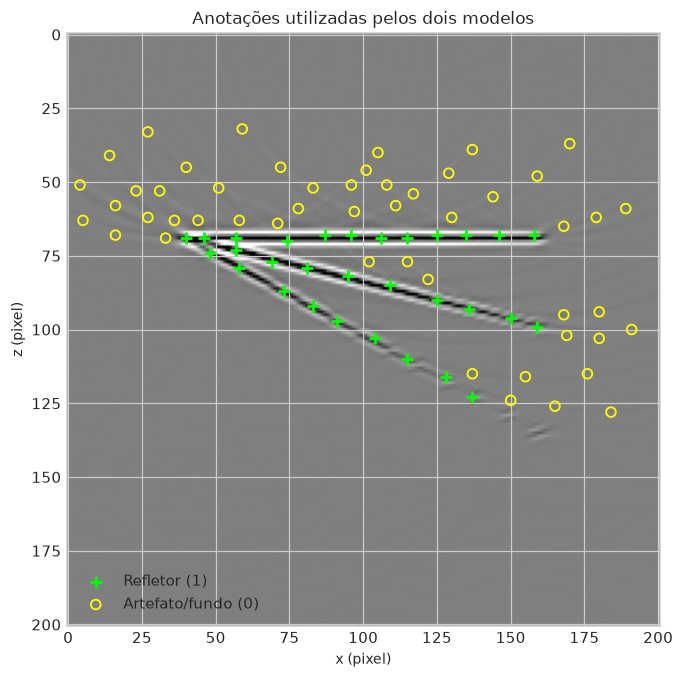

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(migration, cmap="gray", vmin=-0.003, vmax=0.003, aspect="equal")
ax.scatter(
    reflector_coordinates[:, 1], reflector_coordinates[:, 0],
    c="lime", marker="+", s=65, linewidths=1.8, label="Refletor (1)"
)
ax.scatter(
    artifact_coordinates[:, 1], artifact_coordinates[:, 0],
    facecolors="none", edgecolors="yellow", marker="o", s=40,
    linewidths=1.2, label="Artefato/fundo (0)"
)
ax.set(title="Anotações utilizadas pelos dois modelos", xlabel="x (pixel)", ylabel="z (pixel)")
ax.legend(loc="lower left")
plt.show()

training_features = feature_cube[coordinates[:, 0], coordinates[:, 1]]
assert training_features.shape == (80, 3)
assert np.isfinite(training_features).all()

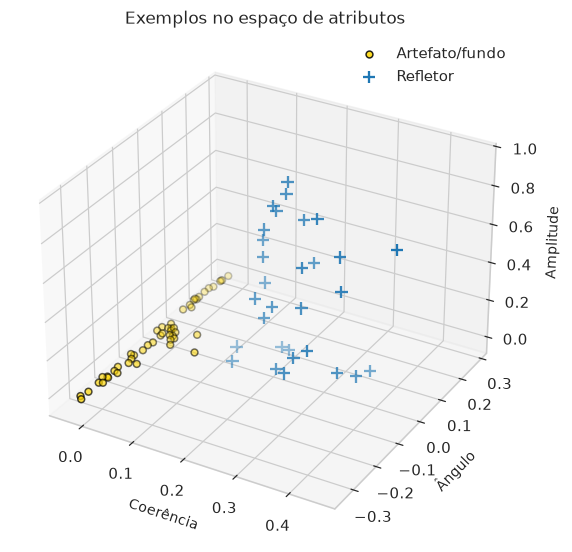

In [7]:
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
artifact = target == 0
reflector = target == 1
ax.scatter(*training_features[artifact].T, c="gold", edgecolor="black", label="Artefato/fundo", alpha=0.85)
ax.scatter(*training_features[reflector].T, c="tab:blue", marker="+", s=65, label="Refletor")
ax.set(
    title="Exemplos no espaço de atributos",
    xlabel="Coerência", ylabel="Ângulo", zlabel="Amplitude"
)
ax.legend()
plt.show()

## 3. FCNN — reprodução do fluxo MATLAB

A FCNN recebe uma expansão de segunda ordem dos três atributos:

$$\phi(x)=(x_1,x_2,x_3,x_1^2,x_2^2,x_3^2,x_1x_2,x_1x_3,x_2x_3).$$

A rede $[9,9,1]$ aplica sigmoide na camada oculta e na saída. Incluindo os bias, há $9(9+1)+1(9+1)=100$ parâmetros. O treinamento usa entropia cruzada e a mesma busca de passo do laboratório: começa em 10 e multiplica o passo por 0,8 enquanto uma atualização aumentar a perda.

In [8]:
def sigmoid(values: np.ndarray) -> np.ndarray:
    values = np.clip(values, -500.0, 500.0)
    return 1.0 / (1.0 + np.exp(-values))


def polynomial_features(features: np.ndarray) -> np.ndarray:
    x1, x2, x3 = features.T
    return np.column_stack([
        x1, x2, x3,
        x1**2, x2**2, x3**2,
        x1 * x2, x1 * x3, x2 * x3,
    ])


def unpack_fcnn(parameters: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    theta1 = parameters[:90].reshape(9, 10)
    theta2 = parameters[90:].reshape(1, 10)
    return theta1, theta2


def fcnn_probability(parameters: np.ndarray, features: np.ndarray) -> np.ndarray:
    theta1, theta2 = unpack_fcnn(parameters)
    expanded = polynomial_features(features)
    input_with_bias = np.column_stack([np.ones(len(features)), expanded])
    hidden = sigmoid(input_with_bias @ theta1.T)
    hidden_with_bias = np.column_stack([np.ones(len(features)), hidden])
    return sigmoid(hidden_with_bias @ theta2.T).ravel()


def fcnn_loss_gradient(
    parameters: np.ndarray,
    features: np.ndarray,
    labels: np.ndarray,
) -> tuple[float, np.ndarray]:
    theta1, theta2 = unpack_fcnn(parameters)
    expanded = polynomial_features(features)
    input_with_bias = np.column_stack([np.ones(len(features)), expanded])
    hidden = sigmoid(input_with_bias @ theta1.T)
    hidden_with_bias = np.column_stack([np.ones(len(features)), hidden])
    probability = sigmoid(hidden_with_bias @ theta2.T).ravel()

    clipped = np.clip(probability, 1e-12, 1.0 - 1e-12)
    loss = float(-np.mean(labels * np.log(clipped) + (1 - labels) * np.log1p(-clipped)))

    output_delta = (probability - labels)[:, None]
    theta2_gradient = output_delta.T @ hidden_with_bias / len(features)
    hidden_delta = (output_delta @ theta2[:, 1:]) * hidden * (1.0 - hidden)
    theta1_gradient = hidden_delta.T @ input_with_bias / len(features)
    gradient = np.r_[theta1_gradient.ravel(), theta2_gradient.ravel()]
    return loss, gradient


def train_fcnn(
    features: np.ndarray,
    labels: np.ndarray,
    iterations: int = 500,
    initial_step: float = 10.0,
    reduction: float = 0.8,
    seed: int = RANDOM_SEED,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    parameters = rng.random(100) - 0.5
    step = initial_step
    losses = np.empty(iterations)
    steps = np.empty(iterations)

    for iteration in range(iterations):
        loss, gradient = fcnn_loss_gradient(parameters, features, labels)
        losses[iteration] = loss
        while True:
            candidate = parameters - step * gradient
            candidate_loss, _ = fcnn_loss_gradient(candidate, features, labels)
            if candidate_loss <= loss:
                break
            step *= reduction
            if step < 1e-12:
                raise RuntimeError("A busca de passo da FCNN não encontrou uma atualização descendente")
        parameters = candidate
        steps[iteration] = step
    return parameters, losses, steps

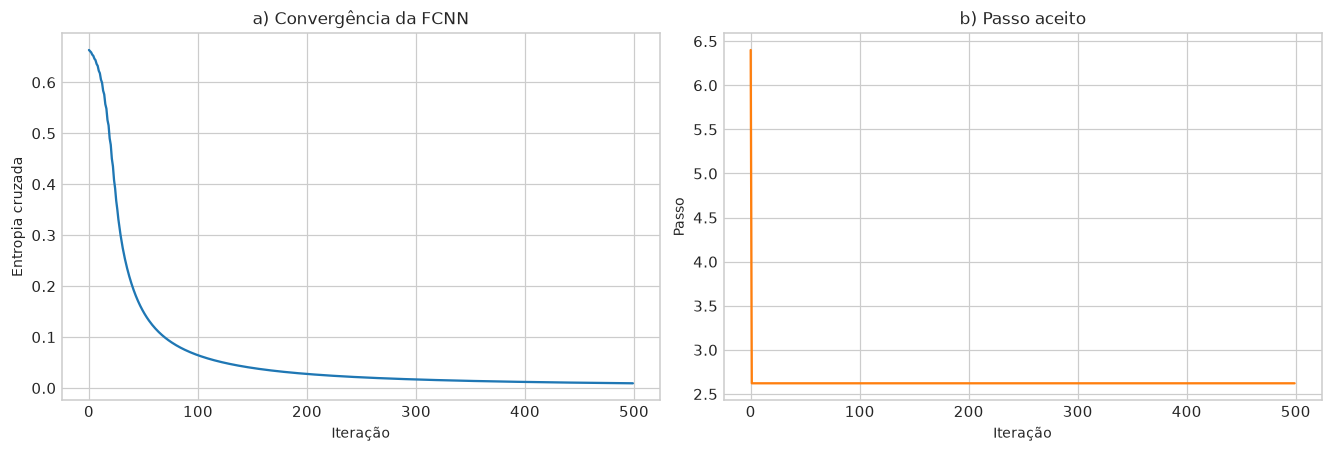

Perda inicial: 0.663484
Perda final:   0.009275
Passo final:   2.621440


In [9]:
fcnn_parameters, fcnn_losses, fcnn_steps = train_fcnn(training_features, target)

assert fcnn_parameters.size == 100
assert np.isfinite(fcnn_losses).all()
assert np.all(np.diff(fcnn_losses) <= 1e-12)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(fcnn_losses, color="tab:blue")
axes[0].set(title="a) Convergência da FCNN", xlabel="Iteração", ylabel="Entropia cruzada")
axes[1].plot(fcnn_steps, color="tab:orange")
axes[1].set(title="b) Passo aceito", xlabel="Iteração", ylabel="Passo")
plt.show()

print(f"Perda inicial: {fcnn_losses[0]:.6f}")
print(f"Perda final:   {fcnn_losses[-1]:.6f}")
print(f"Passo final:   {fcnn_steps[-1]:.6f}")

## 4. SVM com kernel RBF

O kernel gaussiano do MATLAB é

$$K(x,x')=\exp\left(-\frac{\lVert x-x'\rVert^2}{2\sigma^2}\right).$$

O `SVC` usa $\exp(-\gamma\lVert x-x'\rVert^2)$; portanto, para reproduzir $\sigma=0{,}1$, devemos usar $\gamma=1/(2\sigma^2)=50$. O parâmetro de penalidade permanece $C=1$.

In [10]:
C = 1.0
sigma = 0.1
gamma = 1.0 / (2.0 * sigma**2)
assert np.isclose(gamma, 50.0)

svm_rbf = SVC(C=C, kernel="rbf", gamma=gamma)
svm_rbf.fit(training_features, target)

print(f"C = {C:g}; sigma = {sigma:g}; gamma = {gamma:g}")
print(f"Vetores de suporte por classe: {svm_rbf.n_support_.tolist()}")
print(f"Total de vetores de suporte: {int(svm_rbf.n_support_.sum())}")

C = 1; sigma = 0.1; gamma = 50
Vetores de suporte por classe: [12, 21]
Total de vetores de suporte: 33


## 5. Ajuste nos pontos anotados

In [11]:
fcnn_training_probability = fcnn_probability(fcnn_parameters, training_features)
fcnn_training_prediction = (fcnn_training_probability >= 0.5).astype(int)
svm_training_prediction = svm_rbf.predict(training_features).astype(int)


def classification_metrics(name: str, labels: np.ndarray, prediction: np.ndarray) -> dict[str, float | str]:
    return {
        "Modelo": name,
        "Acurácia": accuracy_score(labels, prediction),
        "Precisão (refletor)": precision_score(labels, prediction, zero_division=0),
        "Recall (refletor)": recall_score(labels, prediction, zero_division=0),
        "F1 (refletor)": f1_score(labels, prediction, zero_division=0),
    }


training_metrics = pd.DataFrame([
    classification_metrics("FCNN", target, fcnn_training_prediction),
    classification_metrics("SVM-RBF", target, svm_training_prediction),
]).set_index("Modelo")
training_metrics

,Acurácia,Precisão (refletor),Recall (refletor),F1 (refletor)
Modelo,,,,
FCNN,1,1,1,1
SVM-RBF,1,1,1,1


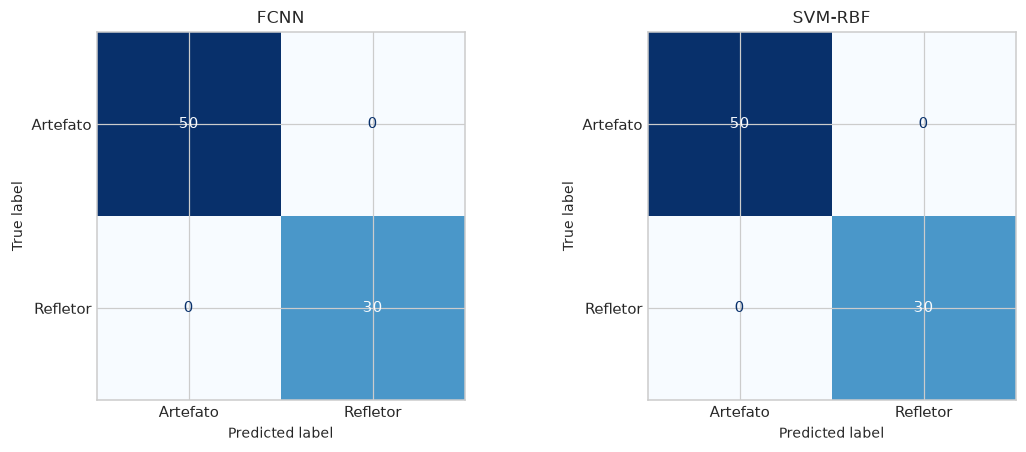

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, name, prediction in [
    (axes[0], "FCNN", fcnn_training_prediction),
    (axes[1], "SVM-RBF", svm_training_prediction),
]:
    matrix = confusion_matrix(target, prediction, labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["Artefato", "Refletor"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)
plt.show()

Na execução apresentada, os dois modelos acertaram os 80 pontos anotados: acurácia, precisão, recall e F1 foram iguais a 1. Portanto, essas métricas não mostram uma vantagem quantitativa da FCNN sobre o SVM neste conjunto.

Como a classe positiva é refletor (`1`), a precisão responde a quanto do que o modelo preserva corresponde realmente a sinal. Já o recall responde a quanto do sinal de referência ele consegue preservar. Um falso positivo preserva artefato ou fundo como refletor; um falso negativo remove um refletor ao atribuir a classe `0`. A acurácia resume os acertos nas duas classes, mas pode esconder essa diferença entre tipos de erro. Aqui, todos os indicadores se referem aos mesmos pontos usados no treinamento; os erros percebidos em outras regiões da imagem não aparecem nessa tabela.

## 6. Classificação e filtragem da imagem completa

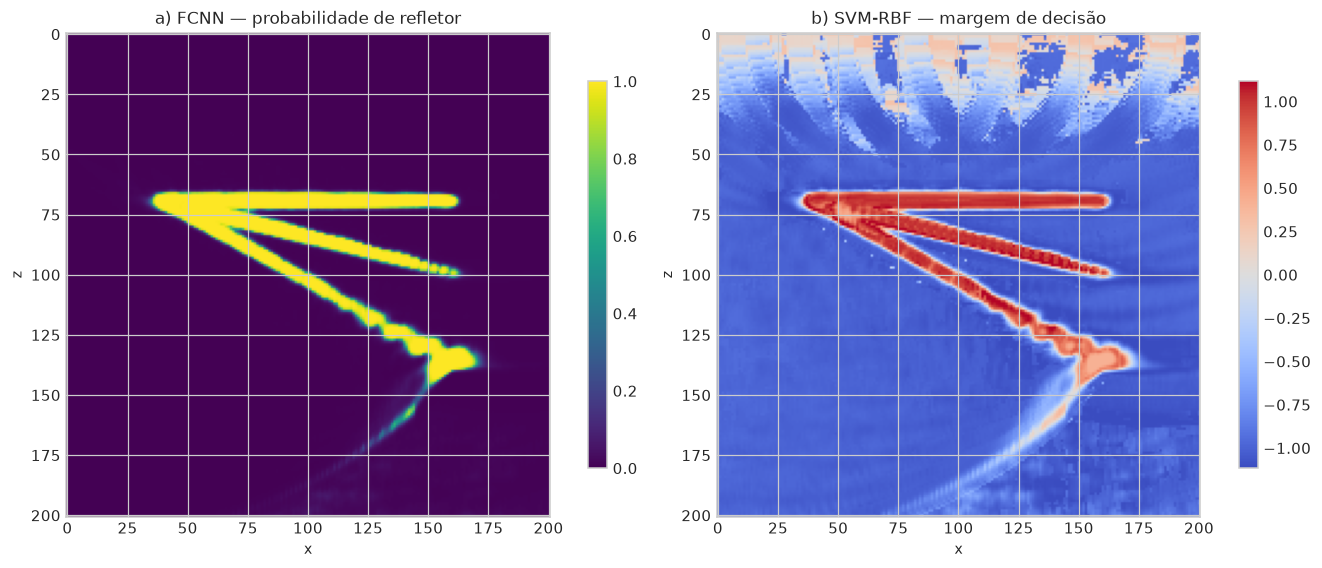

In [13]:
all_features = feature_cube.reshape(-1, 3)
fcnn_probability_map = fcnn_probability(fcnn_parameters, all_features).reshape(migration.shape)
fcnn_mask = fcnn_probability_map >= 0.5
svm_margin_map = svm_rbf.decision_function(all_features).reshape(migration.shape)
svm_mask = svm_margin_map >= 0.0

fcnn_filtered = migration * fcnn_mask
svm_filtered = migration * svm_mask

for name, array in {
    "probabilidade FCNN": fcnn_probability_map,
    "margem SVM": svm_margin_map,
    "máscara FCNN": fcnn_mask,
    "máscara SVM": svm_mask,
    "imagem FCNN": fcnn_filtered,
    "imagem SVM": svm_filtered,
}.items():
    assert array.shape == migration.shape, f"Forma inválida em {name}"
    assert np.isfinite(array).all(), f"Valores não finitos em {name}"

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
image = axes[0].imshow(fcnn_probability_map, cmap="viridis", vmin=0, vmax=1)
axes[0].set(title="a) FCNN — probabilidade de refletor", xlabel="x", ylabel="z")
fig.colorbar(image, ax=axes[0], shrink=0.8)
limit = np.percentile(np.abs(svm_margin_map), 99)
image = axes[1].imshow(svm_margin_map, cmap="coolwarm", vmin=-limit, vmax=limit)
axes[1].set(title="b) SVM-RBF — margem de decisão", xlabel="x", ylabel="z")
fig.colorbar(image, ax=axes[1], shrink=0.8)
plt.show()

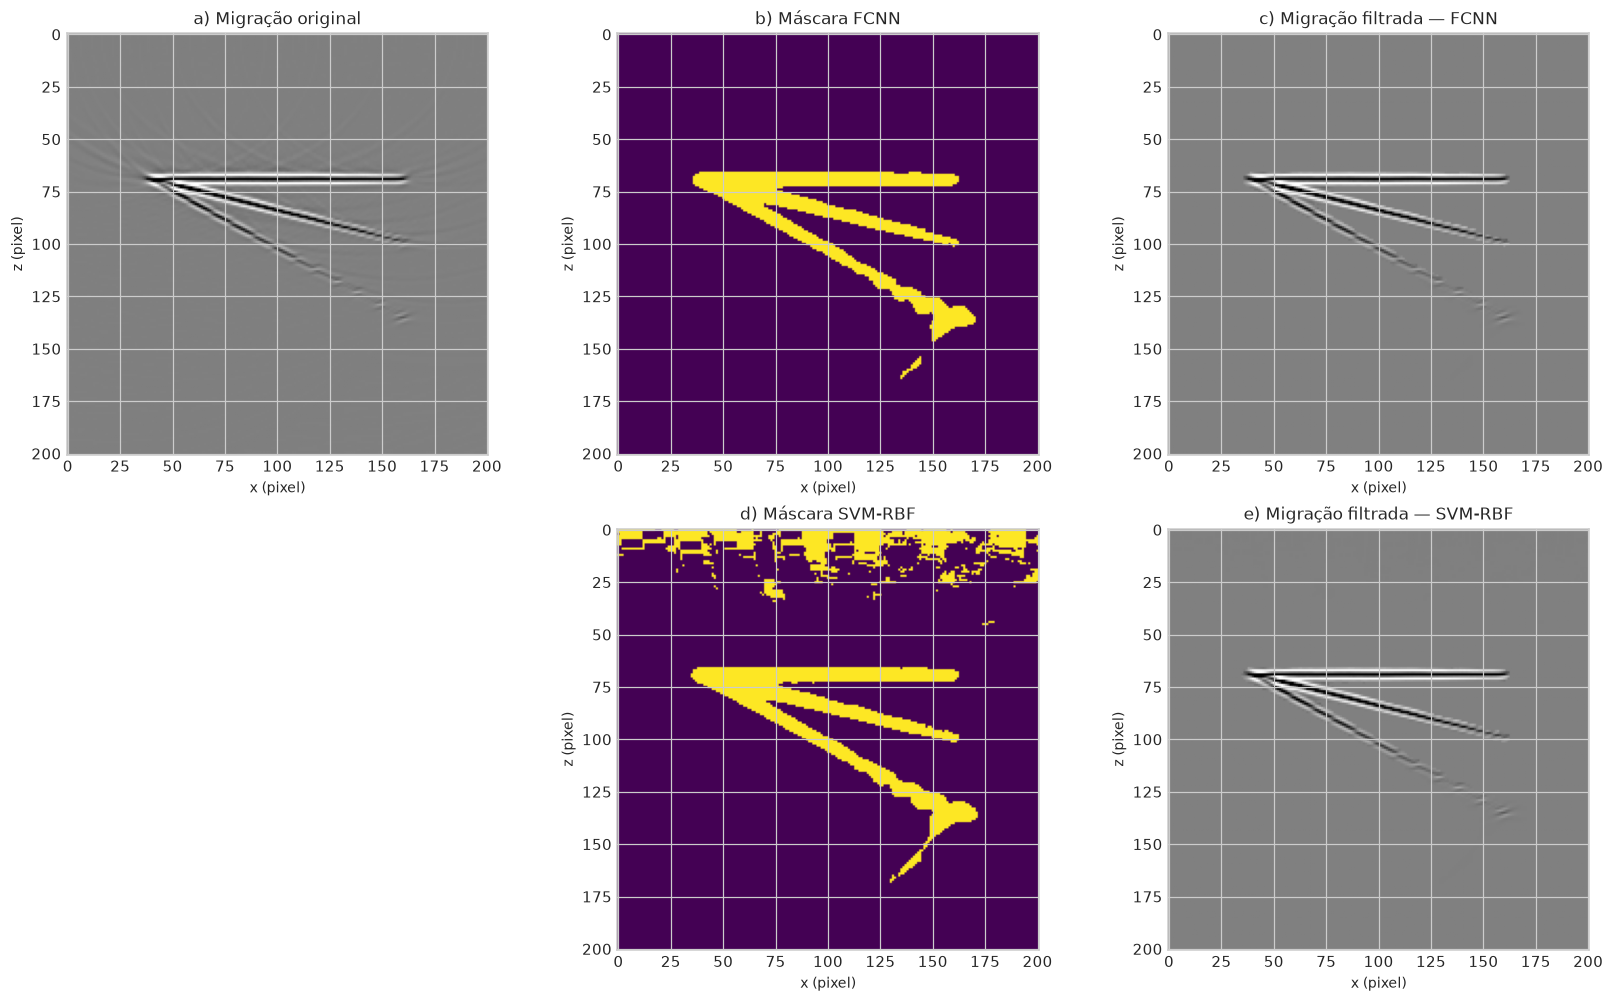

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
axes[0, 0].imshow(migration, cmap="gray", vmin=-0.003, vmax=0.003)
axes[0, 0].set_title("a) Migração original")
axes[0, 1].imshow(fcnn_mask, cmap="viridis")
axes[0, 1].set_title("b) Máscara FCNN")
axes[0, 2].imshow(fcnn_filtered, cmap="gray", vmin=-0.003, vmax=0.003)
axes[0, 2].set_title("c) Migração filtrada — FCNN")
axes[1, 0].axis("off")
axes[1, 1].imshow(svm_mask, cmap="viridis")
axes[1, 1].set_title("d) Máscara SVM-RBF")
axes[1, 2].imshow(svm_filtered, cmap="gray", vmin=-0.003, vmax=0.003)
axes[1, 2].set_title("e) Migração filtrada — SVM-RBF")
for ax in axes.flat:
    if ax.axison:
        ax.set(xlabel="x (pixel)", ylabel="z (pixel)")
plt.show()

## 7. Comparação quantitativa das máscaras

In [17]:
total_energy = float(np.sum(migration**2))
intersection = int(np.sum(fcnn_mask & svm_mask))
union = int(np.sum(fcnn_mask | svm_mask))
pixel_agreement = float(np.mean(fcnn_mask == svm_mask))
signal_iou = intersection / union

mask_metrics = pd.DataFrame([
    {
        "Modelo": "FCNN",
        "Parâmetros/SV": f"{fcnn_parameters.size} parâmetros",
        "Pixels preservados": int(fcnn_mask.sum()),
        "Fração preservada": float(fcnn_mask.mean()),
        "Energia preservada": float(np.sum(fcnn_filtered**2) / total_energy),
    },
    {
        "Modelo": "SVM-RBF",
        "Parâmetros/SV": f"{int(svm_rbf.n_support_.sum())} vetores de suporte",
        "Pixels preservados": int(svm_mask.sum()),
        "Fração preservada": float(svm_mask.mean()),
        "Energia preservada": float(np.sum(svm_filtered**2) / total_energy),
    },
]).set_index("Modelo")

print(f"Concordância pixel a pixel: {pixel_agreement:.2%}")
print(f"IoU das regiões de sinal:   {signal_iou:.2%}")
mask_metrics

Concordância pixel a pixel: 94.91%
IoU das regiões de sinal:   55.25%


,Parâmetros/SV,Pixels preservados,Fração preservada,Energia preservada
Modelo,,,,
FCNN,100 parâmetros,2540,0.0628697,0.994301
SVM-RBF,33 vetores de suporte,4597,0.113784,0.994837


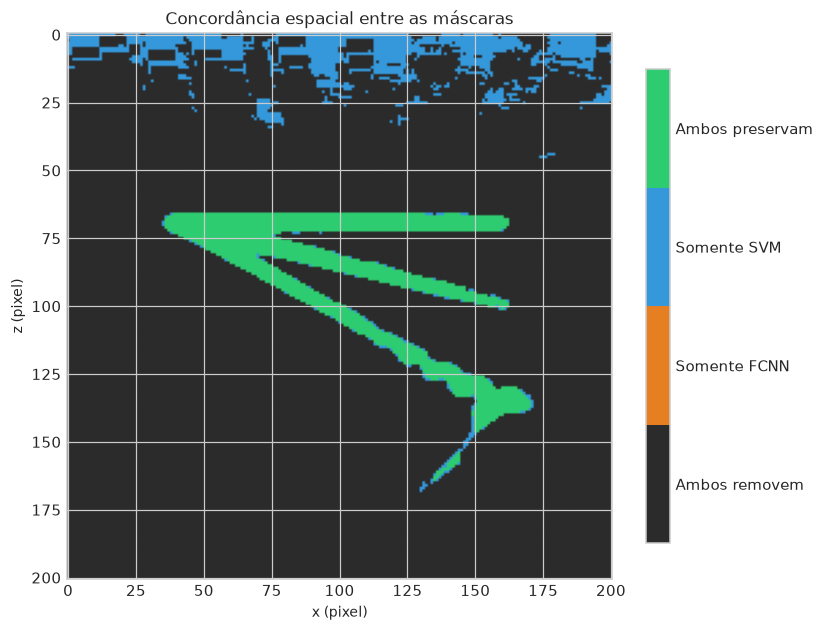

In [18]:
agreement_map = np.zeros(migration.shape, dtype=int)
agreement_map[fcnn_mask & ~svm_mask] = 1
agreement_map[~fcnn_mask & svm_mask] = 2
agreement_map[fcnn_mask & svm_mask] = 3

from matplotlib.colors import ListedColormap

fig, ax = plt.subplots(figsize=(8, 7))
cmap = ListedColormap(["#2b2b2b", "#e67e22", "#3498db", "#2ecc71"])
image = ax.imshow(agreement_map, cmap=cmap, vmin=-0.5, vmax=3.5)
ax.set(title="Concordância espacial entre as máscaras", xlabel="x (pixel)", ylabel="z (pixel)")
colorbar = fig.colorbar(image, ax=ax, ticks=[0, 1, 2, 3], shrink=0.8)
colorbar.ax.set_yticklabels(["Ambos removem", "Somente FCNN", "Somente SVM", "Ambos preservam"])
plt.show()

## 8. Discussão dos resultados

### O ajuste dos pontos e a leitura da imagem

O primeiro resultado que me chamou atenção foi o ajuste perfeito dos dois modelos aos pontos escolhidos. A FCNN reduziu a entropia cruzada de aproximadamente 0,6635 para 0,0093, e o SVM utilizou 33 dos 80 exemplos como vetores de suporte. Isso mostra que ambos conseguiram representar a separação presente nas anotações, mas não garante que aprenderam uma separação fisicamente adequada para toda a imagem.

Ao observar os resultados completos, minha impressão é que os dois métodos preservam boa parte dos refletores principais, mas a FCNN apresenta uma seleção mais consistente de regiões de sinal. Essa impressão é compatível com melhor precisão da FCNN fora dos pontos anotados, principalmente pela presença de possíveis falsos positivos do SVM no topo. Não consigo quantificar essa vantagem com os dados disponíveis: a precisão e o recall medidos no treinamento são idênticos, e não há máscara de referência para medir essas métricas nos demais pixels.

A diferença de representação ajuda a interpretar o comportamento. A FCNN combina uma expansão quadrática explícita com uma camada de sigmoides. O SVM constrói a decisão a partir de similaridades RBF com os vetores de suporte. Pixels distantes na imagem podem ter atributos semelhantes e receber a mesma classe; assim, nenhuma dessas representações impõe, por si só, continuidade espacial ou plausibilidade geológica.

### Onde a filtragem funciona e onde ela me parece falhar

A principal diferença que observei está no topo da imagem: a máscara do SVM preserva algumas regiões que não interpreto como refletores. Visualmente, isso dá a impressão de que o método criou novos “artefatos”. Contudo, a imagem filtrada é apenas a migração original multiplicada por uma máscara binária; o SVM não gera novas amplitudes. O problema é preservar estruturas já existentes que deveriam ser removidas, deixando-as mais evidentes depois da filtragem. Se essa interpretação estiver correta, são falsos positivos da classe `1`.

Também percebi resultados questionáveis no trecho entre aproximadamente $(x,z)=(100,125)$ e $(175,175)$, usando a ordem dos eixos das figuras. Em alguns segmentos, os modelos parecem atribuir a classe de artefato onde espero uma continuação do refletor. Se esses segmentos forem de fato sinal, trata-se de falsos negativos: a máscara remove parte de uma interface que deveria continuar. Esse é um ponto em que minha interpretação geofísica ainda precisa ser confirmada; a descontinuidade visual levanta a suspeita, mas não fornece sozinha um rótulo de referência.

Os números da máscara reforçam que o empate no treinamento não significa filtragens iguais. A FCNN preservou 2.540 pixels (6,29% da imagem), enquanto o SVM preservou 4.597 (11,38%). A energia preservada ficou muito próxima: 99,43% e 99,48%, respectivamente. Assim, a seleção adicional do SVM acrescentou pouca energia, o que é compatível com a preservação de regiões fracas. Isso não prova que essas regiões sejam todas artefatos, assim como preservar menos pixels não torna automaticamente a FCNN melhor.

A concordância global foi de 94,91%, mas a IoU das regiões de sinal ficou em 55,25%. A diferença faz sentido porque grande parte da imagem é removida pelos dois modelos: os muitos pixels de fundo aumentam a concordância global. A IoU evidencia melhor a divergência nas regiões que efetivamente queremos preservar. Para este exercício, considero a continuidade dos refletores e a ausência de regiões espúrias mais informativas do que a energia preservada isoladamente.

### Custo computacional e limites da comparação

A FCNN é pequena: tem 100 parâmetros e realiza 500 atualizações em lote completo sobre 80 exemplos. A busca de passo pode exigir avaliações adicionais da perda. Na aplicação aos 40.401 pixels, o custo por pixel depende da arquitetura fixa, e a implementação consegue processar a imagem com operações matriciais. Portanto, o tamanho do conjunto de treinamento não aumenta diretamente o custo de inferência depois de a rede estar treinada.

No SVM, o treinamento resolve um problema de otimização baseado no kernel, e sua escalabilidade tende a ser mais limitada quando aumentamos bastante o número de exemplos. Na inferência desta execução, cada pixel é comparado aos 33 vetores de suporte, totalizando aproximadamente 1,33 milhão de avaliações do kernel RBF para a imagem. A quantidade de vetores de suporte, portanto, afeta diretamente esse custo. Ainda assim, com apenas 80 exemplos, ambos os métodos são pequenos; comparar 100 parâmetros com 33 vetores de suporte não permite concluir qual é mais rápido. Não foram registrados tempos de execução, então a comparação de custo aqui é estrutural, e não um benchmark.

A anotação manual é outra fonte importante de variação. Escolher pontos sobre eventos evidentes facilita o ajuste, mas pode deixar o topo da imagem e as continuações fracas pouco representados no treinamento. Uma hipótese para os erros observados é que os atributos dessas regiões sejam semelhantes aos de exemplos da outra classe. Confirmar essa hipótese exigiria examinar os atributos e obter novos rótulos nessas regiões.

Mantive os hiperparâmetros do laboratório: nove neurônios, 500 iterações, $C=1$ e $\sigma=0{,}1$. Por isso, os resultados descrevem essas configurações e esta seleção de pontos, não uma superioridade geral de FCNN ou SVM. Como próximo passo de avaliação, seria útil anotar pontos independentes justamente no topo e no trecho mais profundo. Isso permitiria verificar se a melhor precisão visual da FCNN se mantém e quanto sinal cada modelo está removendo.

## Conclusões

Neste experimento, os dois modelos ajustaram perfeitamente os pontos de treinamento, mas a inspeção da imagem mostrou diferenças que a acurácia não capturou. Minha preferência, para esta execução, é pela filtragem da FCNN: ela parece preservar os eventos principais com menos regiões espúrias, enquanto o SVM mantém algumas estruturas no topo que não interpreto como sinal.

Essa preferência não elimina os problemas da FCNN. No trecho mais profundo, ambos apresentam decisões que podem interromper refletores, e essas regiões merecem uma análise geofísica mais cuidadosa. A principal aprendizagem deste exercício foi justamente perceber que um bom classificador nos pontos anotados pode produzir uma filtragem questionável quando aplicado à imagem completa.

Os resultados quantitativos e visuais se complementam: precisão e recall distinguem preservação indevida e remoção de sinal, mas só podem ser medidos onde há referência; energia e concordância entre máscaras descrevem a filtragem, sem validar sua interpretação física. Para afirmar qual método funciona melhor fora do treinamento, eu precisaria de novas anotações independentes.